# Educational Content Summarization System — NLP Pipeline Showcase

- **Course:** `2311217L – Natural Language Processing Lab`
- **Team Members:** Swapnil Santosh Akhade · Sudarshan Sakharam Bansode
- **Mentor:** Prof. Shruti Gadewar

### Table of Contents
- **Section 0:** Setup & Project Data Paths
- **Section 1:** Ingestion & Text Preprocessing (Stages 1–6)
- **Section 2:** Vectorization & Extractive Summarization (Stages 7–8)
- **Section 3:** Information Extraction & Topic Modeling (Stages 9–10)
- **Section 4:** Abstractive Study Notes with Google Gemini (Stage 11)
- **Section 5:** Student Feedback Sentiment Analysis (VADER)
- **Section 6:** Evaluation Benchmark & Visual Summary

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# Point Python to our modular src/ package
PROJECT_ROOT = Path.cwd()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from utils.config import load_config

# Load configuration safely from .env (never print the API key)
cfg = load_config()
PDF_PATH = PROJECT_ROOT / "data" / "raw" / "educational_content_nlp_test_document.pdf"
BENCHMARK_PATH = PROJECT_ROOT / "data" / "evaluation" / "reports" / "benchmark_report.json"

pd.set_option("display.max_colwidth", 95)

print(f"Canonical test PDF : {PDF_PATH.relative_to(PROJECT_ROOT)} (exists={PDF_PATH.exists()})")
print(f"Benchmark report   : {BENCHMARK_PATH.relative_to(PROJECT_ROOT)} (exists={BENCHMARK_PATH.exists()})")
print(f"Gemini configured  : {cfg.is_configured} (model={cfg.model_id})")

Canonical test PDF : data\raw\educational_content_nlp_test_document.pdf (exists=True)
Benchmark report   : data\evaluation\reports\benchmark_report.json (exists=True)
Gemini configured  : True (model=gemini-3.5-flash-lite)


## Section 1: Ingestion & Text Preprocessing (Stages 1–6)

### Stage 1 – PDF Text Extraction (`PyMuPDF`)
This step reads the uploaded PDF page by page and pulls out its raw text so later NLP stages can analyze it.
It also reports document size, page count, word count, and any warnings (for example, if a PDF is scanned).

In [2]:
from extraction.text_extractor import extract_document

pdf_bytes = PDF_PATH.read_bytes()
doc_result = extract_document(PDF_PATH.name, pdf_bytes)
raw_text = doc_result.extracted_text

print(f"Filename   : {doc_result.filename} ({len(pdf_bytes) / 1024:.2f} KB)")
print(f"Pages      : {doc_result.page_count}")
print(f"Characters : {len(raw_text):,}")
print(f"Words      : {len(raw_text.split()):,}")
print(f"Warnings   : {doc_result.extraction_warnings or 'None'}")
print("\nPreview (first 300 characters):")
print("-" * 60)
print(raw_text[:300] + "...")

Filename   : educational_content_nlp_test_document.pdf (7.20 KB)
Pages      : 7
Characters : 5,530
Words      : 730
Warnings   : None

Preview (first 300 characters):
------------------------------------------------------------
Page 1: Foundations of Artificial Intelligence
Artificial Intelligence is defined as the branch of computer science dedicated to creating
computational systems capable of performing tasks that typically require human intelligence. Alan
Turing introduced the Turing Test in 1950 at the University of M...


### Stage 2 – Sentence Tokenization (`NLTK Punkt`)
Sentence tokenization breaks the continuous document text into individual sentences using punctuation and capitalization cues.
Clean sentence boundaries are essential because extractive summarization and definition extraction work one sentence at a time.

In [3]:
from preprocessing.text_preprocessing import tokenize_sentences

sentences = tokenize_sentences(raw_text)

print(f"Total sentences: {len(sentences)}\n")
for idx, sent in enumerate(sentences[:3], start=1):
    compact = " ".join(sent.split())
    print(f"{idx}. {compact}")

Total sentences: 41

1. Page 1: Foundations of Artificial Intelligence Artificial Intelligence is defined as the branch of computer science dedicated to creating computational systems capable of performing tasks that typically require human intelligence.
2. Alan Turing introduced the Turing Test in 1950 at the University of Manchester to evaluate machine intelligence.
3. Symbolic artificial intelligence relies on explicit logical rules and knowledge representation.


### Stage 3 – Word Tokenization (`NLTK`)
Word tokenization splits the text into smaller pieces called tokens—individual words, numbers, and punctuation marks.
Breaking text into tokens lets us filter out filler words and count term importance accurately.

In [4]:
from preprocessing.text_preprocessing import tokenize_words

word_tokens = tokenize_words(raw_text)

print(f"Total word tokens : {len(word_tokens):,}")
print(f"First 20 tokens   : {word_tokens[:20]}")

Total word tokens : 809
First 20 tokens   : ['Page', '1', ':', 'Foundations', 'of', 'Artificial', 'Intelligence', 'Artificial', 'Intelligence', 'is', 'defined', 'as', 'the', 'branch', 'of', 'computer', 'science', 'dedicated', 'to', 'creating']


### Stage 4 – Text Cleaning
Raw text copied from PDFs often has hidden control characters, uneven spacing, and mixed capitalization.
Cleaning standardizes Unicode characters, lowercases the text, and collapses extra spaces so identical words match cleanly.

In [5]:
from preprocessing.text_preprocessing import clean_text

cleaned_text = clean_text(raw_text)

print(f"Characters before cleaning : {len(raw_text):,}")
print(f"Characters after cleaning  : {len(cleaned_text):,}")
print("\nCleaned snippet (first 250 characters):")
print("-" * 60)
print(cleaned_text[:250] + "...")

Characters before cleaning : 5,530
Characters after cleaning  : 5,518

Cleaned snippet (first 250 characters):
------------------------------------------------------------
page 1: foundations of artificial intelligence artificial intelligence is defined as the branch of computer science dedicated to creating computational systems capable of performing tasks that typically require human intelligence. alan turing introdu...


### Stage 5 – Negation-Safe Stopword Removal
Common filler words like *"the"*, *"is"*, and *"of"* add noise without carrying topic meaning, so we remove them along with pure punctuation.
However, our pipeline protects negation words (`no`, `not`, `never`) so the meaning of a statement is never accidentally flipped.

In [6]:
from preprocessing.text_preprocessing import PROTECTED_NEGATIONS, remove_stopwords

filtered_tokens = remove_stopwords(word_tokens)
filtered_lower_set = {t.lower() for t in filtered_tokens}
removed_stopwords = [
    t.lower()
    for t in word_tokens
    if any(ch.isalnum() for ch in t) and t.lower() not in filtered_lower_set
]
negations_kept = sorted(PROTECTED_NEGATIONS & filtered_lower_set)

print(f"Stopwords removed       : {len(removed_stopwords)} total ({len(set(removed_stopwords))} unique)")
print(f"Retained content tokens : {len(filtered_tokens)}")
print(f"Protected negations     : {sorted(PROTECTED_NEGATIONS)} -> Present & kept: {negations_kept}")
print(f"First 15 retained tokens: {filtered_tokens[:15]}")

Stopwords removed       : 189 total (36 unique)
Retained content tokens : 541
Protected negations     : ['never', 'no', 'not'] -> Present & kept: ['never', 'no', 'not']
First 15 retained tokens: ['Page', '1', 'Foundations', 'Artificial', 'Intelligence', 'Artificial', 'Intelligence', 'defined', 'branch', 'computer', 'science', 'dedicated', 'creating', 'computational', 'systems']


### Stage 6 – POS-Aware Lemmatization (`WordNet`)
Lemmatization converts word variations (like *"models"* or *"algorithms"*) back to their dictionary base form using part-of-speech tags.
This groups related word forms together while keeping technical terms such as *"learning"* and *"processing"* readable.

In [7]:
from preprocessing.text_preprocessing import lemmatize_tokens

lemmatized_tokens = lemmatize_tokens(filtered_tokens)
pairs = list(zip(filtered_tokens, lemmatized_tokens))
changed_count = sum(1 for orig, lem in pairs if orig.lower() != lem.lower())

# Show a tidy mix of reduced words and protected technical terms
interesting_rows = []
seen = set()
for orig, lem in pairs:
    key = (orig.lower(), lem)
    if key in seen:
        continue
    if orig.lower() != lem or orig.lower() in {"learning", "processing", "modeling", "training"}:
        seen.add(key)
        interesting_rows.append({
            "Original Token": orig,
            "Lemma": lem,
            "Status": "Protected technical term" if orig.lower() == lem else "Reduced to base form",
        })
    if len(interesting_rows) >= 12:
        break

print(f"Total lemmas: {len(lemmatized_tokens)} | Morphologically reduced: {changed_count}")
display(pd.DataFrame(interesting_rows))

Total lemmas: 541 | Morphologically reduced: 135


,Original Token,Lemma,Status
0,Foundations,foundation,Reduced to base form
1,defined,define,Reduced to base form
2,dedicated,dedicate,Reduced to base form
3,creating,create,Reduced to base form
4,systems,system,Reduced to base form
5,performing,perform,Reduced to base form
6,tasks,task,Reduced to base form
7,introduced,introduce,Reduced to base form
8,rules,rule,Reduced to base form
9,reasoning,reason,Reduced to base form


## Section 2: Vectorization & Extractive Summarization (Stages 7–8)

### Stage 7 – TF-IDF Vectorization (`scikit-learn`)
Computers cannot do math directly on words, so TF-IDF turns our cleaned, lemmatized tokens into a numeric feature vector.
Terms that appear prominently in the document receive higher weights, highlighting the document's core vocabulary.

In [8]:
from preprocessing.vectorizer import fit_tfidf

tfidf_vectorizer, tfidf_result = fit_tfidf([lemmatized_tokens], top_n=10)

print(f"TF-IDF matrix shape : {tfidf_result.matrix_shape[0]} x {tfidf_result.matrix_shape[1]}")
print(f"Vocabulary size     : {len(tfidf_result.feature_names)} unique terms")

tfidf_df = pd.DataFrame(
    [{"Rank": i, "Term": term, "TF-IDF Weight": round(weight, 4)}
     for i, (term, weight) in enumerate(tfidf_result.top_terms, start=1)]
)
display(tfidf_df)

TF-IDF matrix shape : 1 x 350
Vocabulary size     : 350 unique terms


,Rank,Term,TF-IDF Weight
0,1,artificial,0.2604
1,2,intelligence,0.2604
2,3,learn,0.2343
3,4,machine,0.2083
4,5,model,0.2083
5,6,page,0.2083
6,7,sentence,0.1823
7,8,data,0.1562
8,9,network,0.1562
9,10,topic,0.1562


### Stage 8 – Extractive Summarization (`TextRank`)
TextRank builds a similarity network of all sentences using TF-IDF cosine similarity and runs PageRank to score which sentences are most central.
Because it picks original sentences verbatim in their natural reading order, it works 100% offline with zero hallucination.

In [9]:
from summarization.textrank import summarize_text

textrank_result = summarize_text(raw_text, num_sentences=3)

print(f"Similarity graph  : {textrank_result.graph_nodes} nodes, {textrank_result.graph_edges} edges")
print(f"Original words    : {textrank_result.original_word_count}")
print(f"Summary words     : {textrank_result.summary_word_count}")
print(f"Compression ratio : {textrank_result.compression_ratio * 100:.2f}%\n")

print("Selected 3-Sentence Extractive Summary (in document order):")
print("-" * 60)
for idx, sent in enumerate(textrank_result.selected_sentences, start=1):
    score = textrank_result.sentence_scores.get(sent, 0.0)
    print(f"{idx}. [PageRank={score:.4f}] {sent}")

Similarity graph  : 41 nodes, 486 edges
Original words    : 730
Summary words     : 58
Compression ratio : 7.95%

Selected 3-Sentence Extractive Summary (in document order):
------------------------------------------------------------
1. [PageRank=0.0435] Artificial Intelligence is defined as the branch of computer science dedicated to creating computational systems capable of performing tasks that typically require human intelligence.
2. [PageRank=0.0386] Deep Learning is a specialized branch of machine learning based on artificial neural networks with multiple hidden layers.
3. [PageRank=0.0378] TextRank is defined as an unsupervised graph-based ranking algorithm for extractive text summarization and keyword extraction.


## Section 3: Information Extraction & Topic Modeling (Stages 9–10)

### Stage 9A – Named Entity Recognition & Keyphrases (`spaCy en_core_web_sm`)
Named Entity Recognition automatically spots people, organizations, dates, and locations mentioned in study material.
In the same pass, noun-chunk keyphrase extraction ranks important multi-word phrases students should focus on.

In [10]:
from information_extraction.concept_extractor import extract_concepts

concepts_result = extract_concepts(raw_text, top_n_keyphrases=10)

print(f"Named entities extracted : {len(concepts_result.entities)} (showing first 12)")
entities_df = pd.DataFrame([
    {"Entity": e.text, "Label": e.label, "Char Span": f"{e.start}–{e.end}"}
    for e in concepts_result.entities[:12]
])
display(entities_df)

print("\nTop 10 Noun-Chunk Keyphrases:")
keyphrases_df = pd.DataFrame([
    {"Rank": i, "Keyphrase": kp.text, "Score": round(kp.score, 2)}
    for i, kp in enumerate(concepts_result.keyphrases, start=1)
])
display(keyphrases_df)

Named entities extracted : 49 (showing first 12)


,Entity,Label,Char Span
0,1,CARDINAL,5–6
1,Alan\nTuring,PERSON,231–242
2,the Turing Test,WORK_OF_ART,254–269
3,1950,DATE,273–277
4,the University of Manchester,ORG,281–309
5,Symbolic,PERSON,344–352
6,Stanford University,ORG,562–581
7,MIT,ORG,583–586
8,Google DeepMind,PRODUCT,592–607
9,Arthur Samuel,PERSON,997–1010



Top 10 Noun-Chunk Keyphrases:


,Rank,Keyphrase,Score
0,1,Page,3.0
1,2,Deep Learning,2.1
2,3,artificial intelligence,2.1
3,4,computer science,2.1
4,5,TextRank,2.0
5,6,algorithms,2.0
6,7,words,2.0
7,8,Natural Language Processing Intrinsic and extrinsic evaluation frameworks,1.7
8,9,Natural Language Processing Pipeline Natural Language Processing,1.6
9,10,a lexicon and rule-based sentiment analysis tool,1.6


### Stage 9B – Rule-Based Definition Extraction
Educational texts frequently introduce key terms using clear phrasing such as *"X is defined as..."*, *"X refers to..."*, or *"X means..."*.
Our regex-based extractor captures these concept–definition pairs automatically to build a quick glossary.

In [11]:
print(f"Formal definitions extracted: {len(concepts_result.definitions)} (showing first 10)")

defs_df = pd.DataFrame([
    {"Concept": d.concept, "Matched Pattern": d.pattern, "Definition": d.definition}
    for d in concepts_result.definitions[:10]
])
display(defs_df)

Formal definitions extracted: 17 (showing first 10)


,Concept,Matched Pattern,Definition
0,Artificial Intelligence,is defined as,the branch of computer science dedicated to creating computational systems capable of perfo...
1,Machine Learning,refers to,a subfield of artificial intelligence that enables algorithms to learn patterns from empiri...
2,Overfitting,means,a phenomenon where a model memorizes training noise rather than generalizing to unseen test...
3,Supervised Learning,is defined as,a machine learning paradigm in which models are trained on labeled input-output pairs
4,Unsupervised Learning,refers to,algorithms that discover hidden structures in unlabeled data
5,Clustering,is a/an/the,primary unsupervised task where K-Means and Hierarchical Clustering group similar data points
6,Principal Component Analysis,is known as,a dimensionality reduction technique that projects high-dimensional features onto orthogona...
7,Deep Learning,is a/an/the,specialized branch of machine learning based on artificial neural networks with multiple hi...
8,Perceptron,is defined as,the fundamental computational unit of a neural network that applies an activation function ...
9,Backpropagation,means,the gradient-based optimization algorithm used to update network weights by minimizing a lo...


### Stage 10 – Topic Modeling (`Bag-of-Words + Batch LDA`)
Latent Dirichlet Allocation (LDA) groups words that frequently appear together across chunks of a document to uncover hidden themes.
Running LDA with a fixed random seed makes the discovered topics repeatable and transparent for academic analysis.

In [12]:
from topic_modeling.lda_model import run_lda

lda_result = run_lda([raw_text], n_topics=3, random_state=42)

print(f"Document chunks : {len(lda_result.chunks)}")
print(f"BoW matrix shape: {lda_result.bow_matrix_shape[0]} x {lda_result.bow_matrix_shape[1]} (vocab={lda_result.vocabulary_size})")
print(f"LDA Perplexity  : {lda_result.perplexity:.2f}")

topics_df = pd.DataFrame([
    {
        "Topic": f"Topic {t.topic_id}",
        "Top 8 Keywords (weight)": ", ".join(
            f"{kw} ({w:.3f})" for kw, w in zip(t.keywords[:8], t.weights[:8])
        ),
    }
    for t in lda_result.topics
])
display(topics_df)

Document chunks : 9
BoW matrix shape: 9 x 346 (vocab=346)
LDA Perplexity  : 415.19


,Topic,Top 8 Keywords (weight)
0,Topic 0,"intelligence (0.030), artificial (0.022), evaluation (0.014), rouge (0.014), human (0.010),..."
1,Topic 1,"learning (0.037), machine (0.021), data (0.018), artificial (0.018), model (0.014), unsuper..."
2,Topic 2,"sentences (0.014), words (0.014), topic (0.011), text (0.010), frequency (0.010), extractiv..."


## Section 4: Abstractive Study Notes with Google Gemini (Stage 11)

### Stage 11 – Gemini Study-Note Synthesis (`gemini-3.5-flash-lite`)
While TextRank copies original sentences, Google Gemini synthesizes fluent, exam-ready study notes using our versioned, hallucination-guarded prompt templates.
If the shared API key is missing, offline, or hits a quota limit (`429`), this cell gracefully falls back without interrupting the rest of the notebook.

In [13]:
from summarization.llm_summarizer import LLMError, generate_summary

if not cfg.is_configured:
    print("Offline fallback: GEMINI_API_KEY is not configured. Stages 1–10 and VADER work 100% locally.")
else:
    try:
        gemini_result = generate_summary(raw_text, summary_type="short", config=cfg)
        print(f"Model: {gemini_result.model_id} | Request chunks: {gemini_result.chunk_count}\n")
        display(Markdown(gemini_result.summary_text))
    except (LLMError, Exception) as exc:
        msg = str(exc)
        if any(tok in msg.lower() for tok in ("429", "quota", "rate", "resource_exhausted")):
            print("Quota notice: Google Gemini temporarily reached its shared rate/quota limit.")
        else:
            print(f"Offline fallback: Gemini could not be reached ({msg}).")
        print("All local NLP stages (Stages 1–10) and VADER Sentiment remain completely unaffected.")

2026-11-23T20:13:47 | INFO | educational_summarizer | Short document optimization: exact token count 1000 fits budget 16000; processing in 1 request.


2026-11-23T20:13:51 | WARNING | educational_summarizer | Transient LLM error on attempt 1/3: Service unavailable (503 UNAVAILABLE): 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}. Retrying in 0.59s


Model: gemini-3.5-flash-lite | Request chunks: 1



## Main Summary
Artificial Intelligence (AI) is a branch of computer science focused on creating systems that perform tasks requiring human intelligence. Key areas include Machine Learning (learning from data without explicit programming), Deep Learning (neural networks with multiple hidden layers), and Natural Language Processing (processing human language). Systems are evaluated using specific metrics to measure accuracy, summarization quality, and predictive performance.

## Key Concepts
- Symbolic AI vs. Modern AI: Symbolic AI relies on explicit logical rules, whereas modern AI integrates probabilistic reasoning, optimization, and statistical learning.
- Machine Learning Pipeline: Includes data collection, preprocessing, feature engineering, model training, and hyperparameter tuning.
- Supervised vs. Unsupervised Learning: Supervised learning uses labeled input-output pairs for classification and regression, while unsupervised learning discovers hidden structures in unlabeled data (e.g., clustering and dimensionality reduction).
- NLP Pipelines: Involves transforming raw text through tokenization, stopword management, lemmatization, and vectorization (TF-IDF).
- Text Summarization and Topic Modeling: Uses algorithms like TextRank for extractive summaries and Latent Dirichlet Allocation (LDA) for topic modeling.

## Important Definitions
- Artificial Intelligence: The branch of computer science dedicated to creating computational systems capable of performing tasks that typically require human intelligence.
- Machine Learning: A subfield of artificial intelligence that enables algorithms to learn patterns from empirical data without being explicitly programmed.
- Overfitting: A phenomenon where a model memorizes training noise rather than generalizing to unseen test examples.
- Perceptron: The fundamental computational unit of a neural network that applies an activation function to a weighted sum of inputs.
- Backpropagation: The gradient-based optimization algorithm used to update network weights by minimizing a loss function.
- Lemmatization: The morphological analysis that reduces inflected words to their dictionary base form called a lemma.
- TextRank: An unsupervised graph-based ranking algorithm for extractive text summarization and keyword extraction.
- Latent Dirichlet Allocation (LDA): A generative probabilistic topic modelling algorithm that assumes each document is a mixture of latent topics.

## Important Points
- Alan Turing introduced the Turing Test in 1950 to evaluate machine intelligence.
- Machine learning models must guard against overfitting using techniques like cross-validation, as regularization never eliminates all variance.
- Deep learning breakthroughs led to the 2018 Turing Award for Geoffrey Hinton, Yann LeCun, and Yoshua Bengio.
- In text preprocessing, stopword removal eliminates high-frequency words, but negations like "no", "not", and "never" must be preserved to retain semantic polarity.
- Evaluation metrics include ROUGE for text summarization, Precision, Recall, and F1-score for classification, and Perplexity for topic modelling.

## Revision Notes
- Remember the distinction between narrow AI and general AI.
- Understand the difference between classification (discrete labels) and regression (continuous values) in supervised learning.
- Know the purpose of Principal Component Analysis (PCA) as a dimensionality reduction technique.
- Keep in mind how TextRank utilizes cosine similarity between sentence TF-IDF vectors and PageRank centrality to generate extractive summaries.

## Section 5: Student Feedback Sentiment Analysis (VADER)

Textbooks and lecture notes are factual, so sentiment analysis is kept strictly separate and applied only to subjective student feedback.
VADER scores each review from `-1` (most negative) to `+1` (most positive) and labels it as Positive, Neutral, or Negative.

In [14]:
from sentiment.sentiment_analyzer import analyze_batch, analyze_feedback

sample_single = "The TextRank walkthrough and similarity matrix made summarization super clear!"
single_res = analyze_feedback(sample_single)
print(f"Single review -> Label: {single_res.sentiment_label} (compound={single_res.compound_score:.4f})\n")

sample_reviews = [
    "Excellent course structure with practical Python labs that reinforce every lecture!",
    "The explanation of LDA topic modeling was rushed and very confusing.",
    "Chapter four covers TF-IDF vectorization, cosine similarity, and inverted indices.",
    "The revision notes and worked examples were super helpful for exam preparation.",
    "Audio quality in the recorded lecture was poor and frustrating to follow.",
]

batch_res = analyze_batch(sample_reviews)
sentiment_df = pd.DataFrame([
    {
        "Student Review": r.feedback_text,
        "Pos": round(r.positive_score, 3),
        "Neu": round(r.neutral_score, 3),
        "Neg": round(r.negative_score, 3),
        "Compound": round(r.compound_score, 4),
        "Predicted Label": r.sentiment_label,
    }
    for r in batch_res.results
])
display(sentiment_df)

print(
    f"Class Summary (n={batch_res.total}): "
    f"Positive={batch_res.positive} ({batch_res.positive_pct:.1f}%), "
    f"Negative={batch_res.negative} ({batch_res.negative_pct:.1f}%), "
    f"Neutral={batch_res.neutral} ({batch_res.neutral_pct:.1f}%)"
)

Single review -> Label: Positive (compound=0.7777)



,Student Review,Pos,Neu,Neg,Compound,Predicted Label
0,Excellent course structure with practical Python labs that reinforce every lecture!,0.285,0.715,0.000,0.6114,Positive
1,The explanation of LDA topic modeling was rushed and very confusing.,0.000,0.820,0.180,-0.2944,Negative
2,"Chapter four covers TF-IDF vectorization, cosine similarity, and inverted indices.",0.000,1.000,0.000,0.0000,Neutral
3,The revision notes and worked examples were super helpful for exam preparation.,0.401,0.599,0.000,0.7717,Positive
4,Audio quality in the recorded lecture was poor and frustrating to follow.,0.000,0.625,0.375,-0.7184,Negative


Class Summary (n=5): Positive=2 (40.0%), Negative=2 (40.0%), Neutral=1 (20.0%)


## Section 6: Evaluation Benchmark & Visual Summary

### Benchmark Tables (Head-to-Head Summarization & Classical Modules)
To measure real system quality objectively, we evaluated every module on our curated academic benchmark suite (`benchmark_report.json`).
Table 1 compares TextRank against Google Gemini across 12 passages, and Table 2 summarizes spaCy NER, regex definitions, and LDA topic modeling.

In [15]:
benchmark = json.loads(BENCHMARK_PATH.read_text(encoding="utf-8"))
sum_res = benchmark["results"]["summarization"]
sent_res = benchmark["results"]["sentiment"]
con_res = benchmark["results"]["concepts"]
top_res = benchmark["results"]["topics"]

# Table 1: Head-to-head TextRank vs Google Gemini (n = 12)
tr_r = sum_res["textrank_macro_rouge"]
gm_r = sum_res["llm_macro_rouge"]

table1_df = pd.DataFrame([
    {
        "Model": "TextRank (Extractive, Offline)",
        "ROUGE-1 F1": round(tr_r["rouge_1"]["f1"], 4),
        "ROUGE-2 F1": round(tr_r["rouge_2"]["f1"], 4),
        "ROUGE-L F1": round(tr_r["rouge_l"]["f1"], 4),
        "Avg Latency (s/doc)": sum_res["textrank_avg_latency_seconds"],
    },
    {
        "Model": f"Google Gemini ({sum_res['llm_model_id']})",
        "ROUGE-1 F1": round(gm_r["rouge_1"]["f1"], 4),
        "ROUGE-2 F1": round(gm_r["rouge_2"]["f1"], 4),
        "ROUGE-L F1": round(gm_r["rouge_l"]["f1"], 4),
        "Avg Latency (s/doc)": sum_res["llm_avg_latency_seconds"],
    },
])
print(f"Table 1: Head-to-Head Summarization Benchmark (n = {sum_res['sample_count']} passages)")
display(table1_df)

# Table 2: Classical Pipeline Module Metrics
ner_m = con_res["entity_metrics"]
def_m = con_res["definition_metrics"]

table2_df = pd.DataFrame([
    {
        "Module": "spaCy NER (en_core_web_sm)",
        "Benchmark Size": f"{con_res['sample_count']} docs ({ner_m['reference_total']} entities)",
        "Precision": round(ner_m["precision"], 4),
        "Recall": round(ner_m["recall"], 4),
        "F1-Score": round(ner_m["f1"], 4),
        "Notes": f"TP={ner_m['true_positives']}, FP={ner_m['false_positives']}, FN={ner_m['false_negatives']}",
    },
    {
        "Module": "Regex Definition Extractor",
        "Benchmark Size": f"{con_res['sample_count']} docs ({def_m['reference_total']} defs)",
        "Precision": round(def_m["precision"], 4),
        "Recall": round(def_m["recall"], 4),
        "F1-Score": round(def_m["f1"], 4),
        "Notes": f"TP={def_m['true_positives']}, FP={def_m['false_positives']}, FN={def_m['false_negatives']}",
    },
    {
        "Module": "Batch LDA (k=3, seed=42)",
        "Benchmark Size": f"{top_res['document_count']} chunks (3 domains)",
        "Precision": "—",
        "Recall": "—",
        "F1-Score": "—",
        "Notes": f"Perplexity={top_res['perplexity']:.2f}, Vocab={top_res['vocabulary_size']}, Reproducible={top_res['reproducible']}",
    },
])
print("\nTable 2: Classical NLP Module Benchmarks")
display(table2_df)

Table 1: Head-to-Head Summarization Benchmark (n = 12 passages)


,Model,ROUGE-1 F1,ROUGE-2 F1,ROUGE-L F1,Avg Latency (s/doc)
0,"TextRank (Extractive, Offline)",0.2484,0.0551,0.1629,0.0170
1,Google Gemini (gemini-3.5-flash-lite),0.3303,0.0941,0.2408,3.0204



Table 2: Classical NLP Module Benchmarks


,Module,Benchmark Size,Precision,Recall,F1-Score,Notes
0,spaCy NER (en_core_web_sm),10 docs (33 entities),0.8857,0.9394,0.9118,"TP=31, FP=4, FN=2"
1,Regex Definition Extractor,10 docs (10 defs),1.0,0.9,0.9474,"TP=9, FP=0, FN=1"
2,"Batch LDA (k=3, seed=42)",15 chunks (3 domains),—,—,—,"Perplexity=605.10, Vocab=395, Reproducible=True"


### Visual Summary: ROUGE Comparison & VADER Confusion Matrix
Charts make model trade-offs immediately clear: on the left, Google Gemini beats TextRank across every ROUGE F1 metric while TextRank runs ~178× faster offline.
On the right, VADER's 3×3 confusion matrix over 60 balanced reviews shows 83.3% accuracy with zero Positive-versus-Negative polarity inversions.

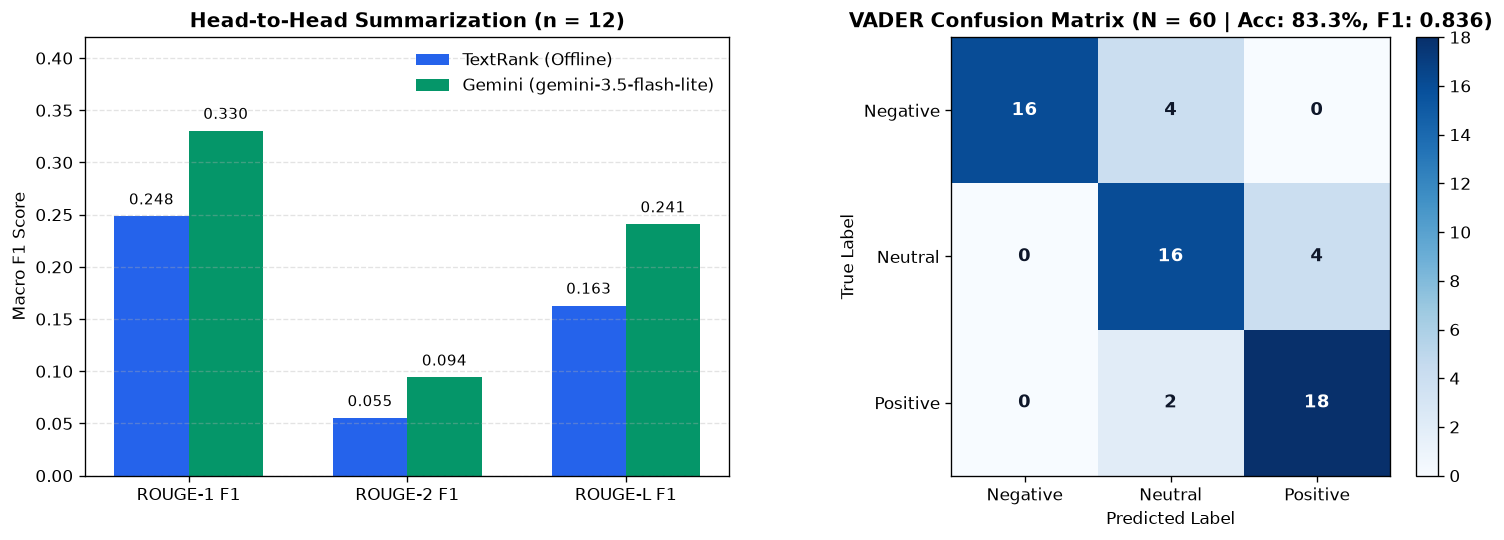

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), dpi=120)

# --- Left Panel: Grouped Bar Chart (TextRank vs Gemini ROUGE F1) ---
ax1 = axes[0]
metrics = ["ROUGE-1 F1", "ROUGE-2 F1", "ROUGE-L F1"]
tr_vals = [tr_r["rouge_1"]["f1"], tr_r["rouge_2"]["f1"], tr_r["rouge_l"]["f1"]]
gm_vals = [gm_r["rouge_1"]["f1"], gm_r["rouge_2"]["f1"], gm_r["rouge_l"]["f1"]]

x = np.arange(len(metrics))
width = 0.34
bars_tr = ax1.bar(x - width / 2, tr_vals, width, label="TextRank (Offline)", color="#2563EB")
bars_gm = ax1.bar(x + width / 2, gm_vals, width, label=f"Gemini ({sum_res['llm_model_id']})", color="#059669")

for bars in (bars_tr, bars_gm):
    for bar in bars:
        h = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width() / 2, h + 0.008, f"{h:.3f}", ha="center", va="bottom", fontsize=9)

ax1.set_title(f"Head-to-Head Summarization (n = {sum_res['sample_count']})", fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(metrics)
ax1.set_ylabel("Macro F1 Score")
ax1.set_ylim(0, 0.42)
ax1.grid(axis="y", linestyle="--", alpha=0.35)
ax1.legend(frameon=False)

# --- Right Panel: 3x3 VADER Confusion Matrix (N = 60) ---
ax2 = axes[1]
cm = np.array(sent_res["metrics"]["confusion_matrix"])
labels = sent_res["metrics"]["labels"]
acc = sent_res["metrics"]["accuracy"] * 100
macro_f1 = sent_res["metrics"]["macro_f1"]

im = ax2.imshow(cm, cmap="Blues", vmin=0)
ax2.set_title(f"VADER Confusion Matrix (N = {sent_res['sample_count']} | Acc: {acc:.1f}%, F1: {macro_f1:.3f})", fontweight="bold")
ax2.set_xticks(range(len(labels)))
ax2.set_yticks(range(len(labels)))
ax2.set_xticklabels(labels)
ax2.set_yticklabels(labels)
ax2.set_xlabel("Predicted Label")
ax2.set_ylabel("True Label")

thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        color = "white" if cm[i, j] > thresh else "#0F172A"
        ax2.text(j, i, str(cm[i, j]), ha="center", va="center", color=color, fontsize=11, fontweight="bold")

fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()